# Part 1 Plots

In [29]:
import os
os.getcwd() # Should be root of repo, if not adjust it accordingly

'/nfs/home/yqy4012/AdvancedAlgos/HW3'

## 1. Implement FedAvg for Federated MNIST dataset -- Data Distribution and 5 Clients

In [30]:
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

DATA_PATH = Path("data/Assignment3-data/train_data.npy")

In [31]:
import numpy as np

NUM_CLIENTS = 100
NUM_CLASSES = 62

train_data = np.load(DATA_PATH, allow_pickle=True)

In [32]:
def client_label(n):
    """Return the labels for a client."""
    y = np.asarray(train_data[n]['labels'])
    return y.astype(np.int64)

In [33]:
counts = np.stack([np.bincount(client_label(k), minlength=NUM_CLASSES) for k in range(NUM_CLIENTS)]) # aggregate across all clients/users
sizes = counts.sum(axis=1)
total = counts.sum(axis=0)

print(f"total samples: {sizes.sum()}")
print(f"samples/client: min={sizes.min()}, median={int(np.median(sizes))}, max={sizes.max()}")
print(f"classes present overall: {(total > 0).sum()}/{NUM_CLASSES}")
print(f"classes present per client: min={(counts > 0).sum(1).min()}, max={(counts > 0).sum(1).max()}")

total samples: 31825
samples/client: min=118, median=331, max=393
classes present overall: 62/62
classes present per client: min=37, max=61


In [21]:
print("missing classes:", np.where(total == 0)[0])
print("label range:", total.nonzero()[0].min(), "-", total.nonzero()[0].max())

missing classes: []
label range: 0 - 61


In [34]:
test_data = np.load("data/Assignment3-data/test_data.npy", allow_pickle=True)
test_labels = np.asarray(test_data[0]['labels'])
if test_labels.ndim > 1:
    test_labels = test_labels.argmax(axis=1)
test_counts = np.bincount(test_labels.astype(int), minlength=NUM_CLASSES)
print("test samples:", len(test_labels))
print("missing in test:", np.where(test_counts == 0)[0])
print("in test but never in train:", np.where((test_counts > 0) & (total == 0))[0])

test samples: 3621
missing in test: []
in test but never in train: []


In [23]:
unseen = np.where(total == 0)[0]
mask = np.isin(test_labels, unseen)
print(f"test samples with unseen classes: {mask.sum()} / {len(test_labels)}")
print(f"max achievable test accuracy: {1 - mask.mean():.4f}")

test samples with unseen classes: 0 / 3621
max achievable test accuracy: 1.0000


overall imbalance: max/min class count = 32.8
TV distance from global: mean=0.18, max=0.35


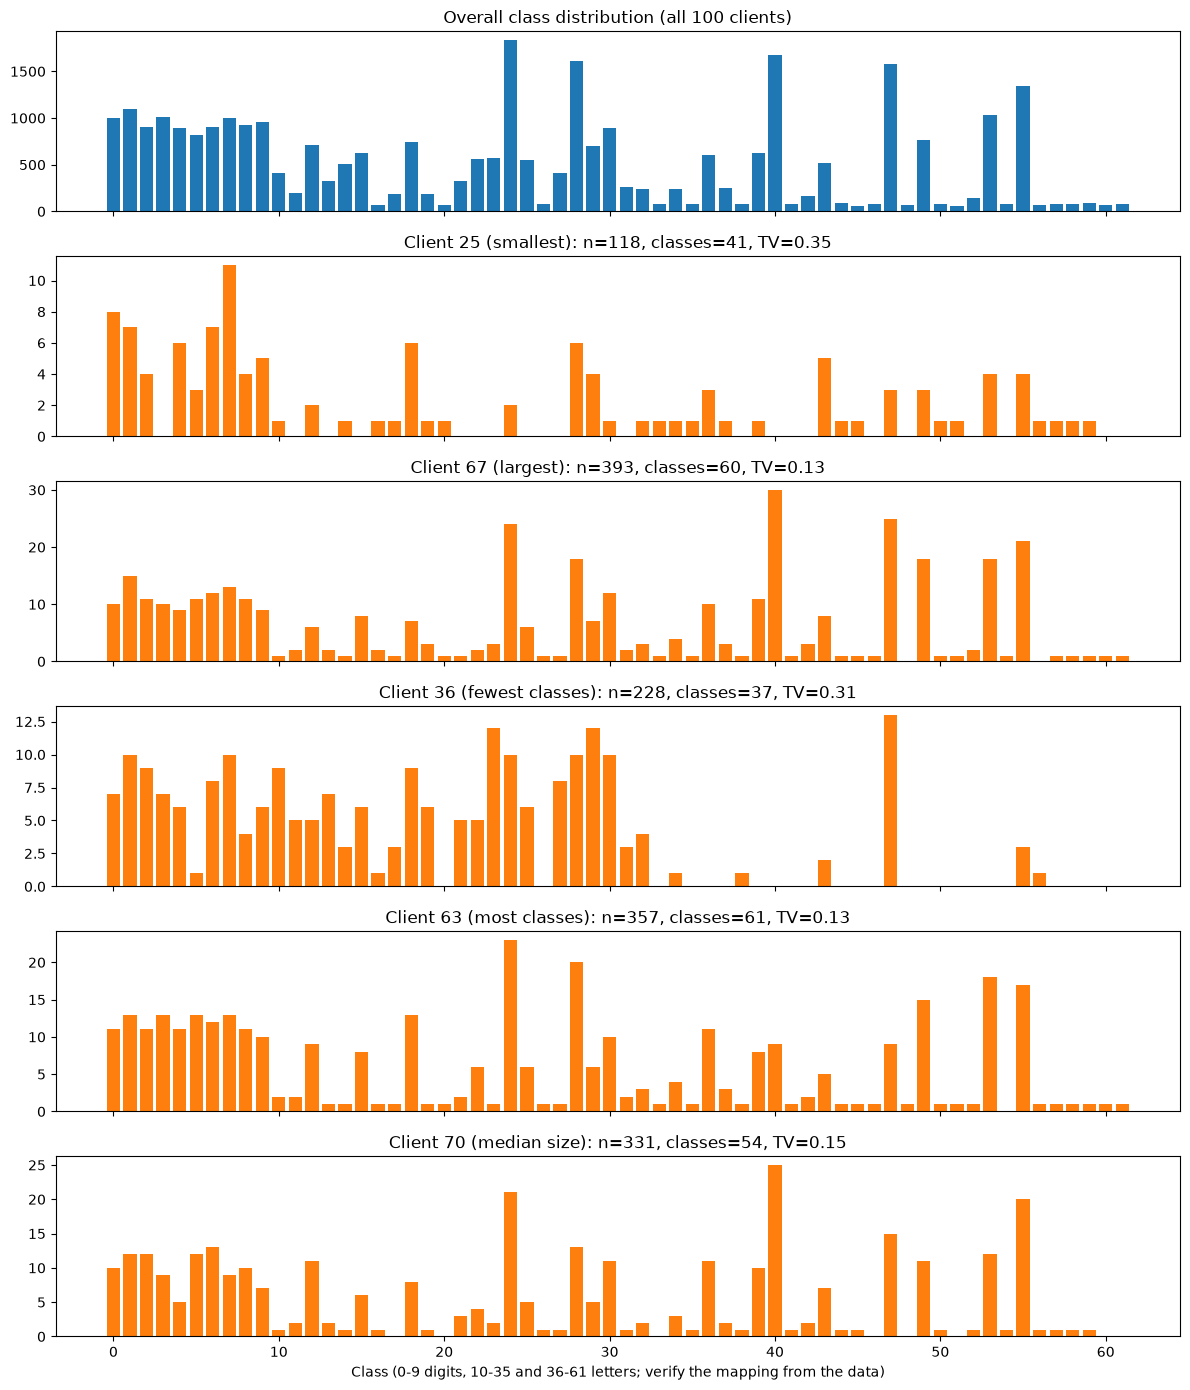

In [25]:
p_global = total / total.sum()
clients_per_class = (counts > 0).sum(0)

# distance of each client's label distribution from the global one
p_client = counts / sizes[:, None]
tv = 0.5 * np.abs(p_client - p_global).sum(1)   # total variation, 0 = identical to global

chosen = {
    "smallest": sizes.argmin(),
    "largest": sizes.argmax(),
    "fewest classes": (counts > 0).sum(1).argmin(),
    "most classes": (counts > 0).sum(1).argmax(),
    "median size": np.argsort(sizes)[len(sizes) // 2],
}

fig, axes = plt.subplots(6, 1, figsize=(12, 14), sharex=True)
axes[0].bar(range(NUM_CLASSES), total)
axes[0].set_title("Overall class distribution (all 100 clients)")
for ax, (name, k) in zip(axes[1:], chosen.items()):
    ax.bar(range(NUM_CLASSES), counts[k], color="tab:orange")
    ax.set_title(f"Client {k} ({name}): n={sizes[k]}, classes={(counts[k] > 0).sum()}, TV={tv[k]:.2f}")
axes[-1].set_xlabel("Class (0-9 digits, 10-35 and 36-61 letters; verify the mapping from the data)")
plt.tight_layout()
plt.savefig("plots/class_distribution.png", dpi=150)
plt.show()

print(f"overall imbalance: max/min class count = {total.max() / total[total > 0].min():.1f}")
print(f"TV distance from global: mean={tv.mean():.2f}, max={tv.max():.2f}")

In [26]:
mins = np.array([np.asarray(train_data[k]['images']).min() for k in range(NUM_CLIENTS)])
maxs = np.array([np.asarray(train_data[k]['images']).max() for k in range(NUM_CLIENTS)])
dtypes = {str(np.asarray(train_data[k]['images']).dtype) for k in range(NUM_CLIENTS)}

print("dtypes:", dtypes)
print("shape of client 0:", np.asarray(train_data[0]['images']).shape)
print(f"global min={mins.min()}, global max={maxs.max()}")
print(f"per-client max: min={maxs.min()}, max={maxs.max()}")
print("clients with max <= 1.5:", (maxs <= 1.5).sum(), "| clients with max > 1.5:", (maxs > 1.5).sum())

dtypes: {'float32'}
shape of client 0: (344, 28, 28)
global min=0.0, global max=1.0
per-client max: min=1.0, max=1.0
clients with max <= 1.5: 100 | clients with max > 1.5: 0


In [27]:
t = np.asarray(test_data[0]['images'])
print("test:", t.shape, t.dtype, t.min(), t.max())

test: (3621, 28, 28) float32 0.0 1.0


In [28]:
all_y = np.concatenate([client_label(k) for k in range(NUM_CLIENTS)])
print(all_y.min(), all_y.max(), np.asarray(test_data[0]['labels']).min(), np.asarray(test_data[0]['labels']).max())

0 61 0 61


In [35]:
X = np.asarray(train_data[0]['images'])
print("mean pixel:", X.mean(), "| frac of pixels > 0.9:", (X > 0.9).mean())

mean pixel: 0.97437024 | frac of pixels > 0.9: 0.9570887221167537


The above code output confirms that the majority of pixels are white. Consider this for preprocessing.